# Analisis Data Eksploratif (EDA) & Visualisasi Dataset Skripsi
### Judul Penelitian: Pemanfaatan Generative Aspect-Based Sentiment Analysis untuk Ekstraksi Insight Layanan Rumah Sakit dari Ulasan Publik Google Maps

Notebook ini dibuat untuk melakukan Exploratory Data Analysis (EDA) terhadap seluruh data raw, data terproses, dan data anotasi (ground truth) yang digunakan dalam penelitian skripsi ini. Hasil analisis dan visualisasi dari notebook ini dapat langsung disalin ke **Bab 3 (Metodologi Penelitian)** dan **Bab 4 (Hasil dan Pembahasan)** pada draf skripsi Anda.

#### Cakupan Analisis:
1. **Analisis Profil Rumah Sakit** (`1_Master_Profil_RS.csv`, `data_rumah_sakit_api.csv`, `merged_data_rumah_sakit.csv`)
2. **Analisis Kamus Normalisasi** (`kamus_normalisasi.csv`)
3. **Analisis Ulasan Google Maps (Raw & Processed)** (`hospital_reviews_gmaps_*.csv`)
4. **Analisis Data Anotasi Manual (Ground Truth GABSA)** (`combined_labeled_data.jsonl`)
5. **Analisis Data Latih Task B (Summary Generation)** (`summary_training_prep.csv`)

In [1]:
# Import library yang dibutuhkan
import os
import glob
import json
import pandas as pd
import numpy as np
import openpyxl
import matplotlib.pyplot as plt
import seaborn as sns

# Set style visualisasi untuk kebutuhan akademik/skripsi
sns.set_theme(style="whitegrid")
plt.rcParams["figure.figsize"] = (10, 6)
plt.rcParams["font.family"] = "sans-serif"
plt.rcParams["font.size"] = 11
plt.rcParams["axes.labelsize"] = 12
plt.rcParams["axes.titlesize"] = 14
plt.rcParams["xtick.labelsize"] = 10
plt.rcParams["ytick.labelsize"] = 10

# Path data
DATA_DIR = "../health_analyze/data"
PLOT_DIR = "plots"

# Buat folder plots jika belum ada
os.makedirs(PLOT_DIR, exist_ok=True)
print("Library berhasil di-import dan visualisasi dikonfigurasi.")

Library berhasil di-import dan visualisasi dikonfigurasi.


## 1. Analisis Profil Rumah Sakit (Data Master & API)
Pada bagian ini kita akan menganalisis data profil rumah sakit resmi yang didapatkan dari Kemenkes (SIRS) dan API untuk mengetahui distribusi geografi, kelas rumah sakit, status kepemilikan, dan jenis pelayanan.

In [2]:
# Load data profil RS yang sudah digabung
path_merged_rs = os.path.join(DATA_DIR, "processed/merged_data_rumah_sakit.csv")

if os.path.exists(path_merged_rs):
    df_rs = pd.read_csv(path_merged_rs, sep=";")
    print(f"Data Master Profil RS berhasil dimuat. Total RS: {df_rs.shape[0]} dengan {df_rs.shape[1]} kolom.")
    display(df_rs.head())
else:
    print(f"File tidak ditemukan di: {path_merged_rs}")

Data Master Profil RS berhasil dimuat. Total RS: 3300 dengan 13 kolom.


,kode,nama,nama_prop,kab,alamat,TELEPON,pemilik,kelas,jenis_rs,status_rs,direktur,luas_tanah,luas_bangunan
0,1171015,RS Umum Daerah Dr. Zainoel Abidin,Aceh,Kota Banda Aceh,"Jalan. Tengku Daud Beureueh, NO. 108 Banda Aceh",0651-34562,Pemprop,A,Rumah Sakit Umum,BLUD,"Dr. Muhazar H. SKM., M.Kes",215193,445104
1,1110101,RS Umum Bireuen Medical Center,Aceh,Bireuen,"Jalan Bireuen-Takengon KM.1,6.",0644-323155,Organisasi Sosial,D,Rumah Sakit Umum,BLU,dr. Lili Yuliani Ridwan,9313,2553
2,1173023,RS Umum Cut Meutia,Aceh,Kota Langsa,Jalan Garuda,-,BUMN,C,Rumah Sakit Umum,Non BLU/BLUD,"dr. Hanafi Nasution, MKM","1,6Ha",3.950M2
3,1112011,RS Umum Daerah Teungku Peukan,Aceh,Aceh Barat Daya,Jl. Nasional Padang Meurante Desa Ujung Padang...,0659-92522,Pemkab,C,Rumah Sakit Umum,BLUD,"dr. ISMAIL MUHAMMAD, Sp.B",59.4,6.517
4,1171143,RS Bhayangkara Banda Aceh,Aceh,Kota Banda Aceh,Jl. Cut Nyak Dhien No. 23,0651-41470,POLRI,C,Rumah Sakit Umum,BLU,dr. Jamal Nasir Husni,2219,2122


/tmp/ipykernel_2086/4283344791.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=class_counts.index, y=class_counts.values, palette="Blues_r")


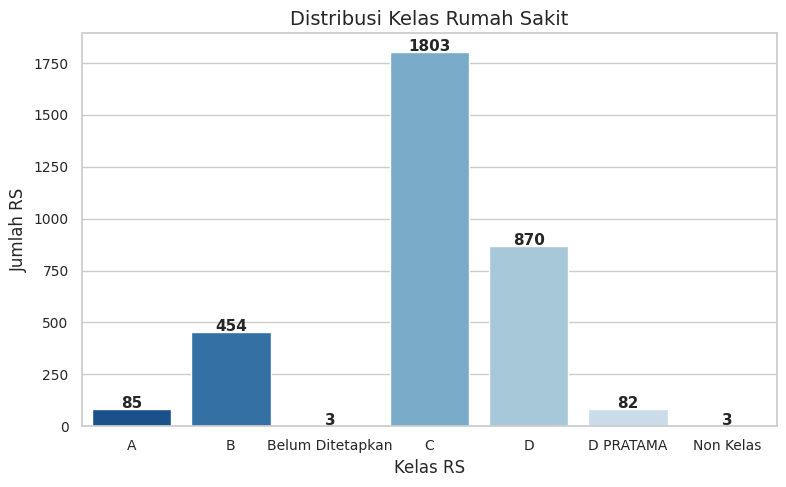

--- Persentase Kelas RS ---
kelas
C                   54.636364
D                   26.363636
B                   13.757576
A                    2.575758
D PRATAMA            2.484848
Belum Ditetapkan     0.090909
Non Kelas            0.090909
Name: proportion, dtype: float64


In [3]:
# 1.1 Distribusi Kelas Rumah Sakit (A, B, C, D)
if 'kelas' in df_rs.columns:
    class_counts = df_rs['kelas'].value_counts().sort_index()
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x=class_counts.index, y=class_counts.values, palette="Blues_r")
    plt.title("Distribusi Kelas Rumah Sakit")
    plt.xlabel("Kelas RS")
    plt.ylabel("Jumlah RS")
    for i, val in enumerate(class_counts.values):
        plt.text(i, val + 5, str(val), ha='center', fontweight='bold')
    
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "distribusi_kelas_rs.png"), dpi=300)
    plt.show()
    
    # Tampilkan persentase
    print("--- Persentase Kelas RS ---")
    print(df_rs['kelas'].value_counts(normalize=True) * 100)

/tmp/ipykernel_2086/412703477.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=owner_counts.index, x=owner_counts.values, palette="viridis")


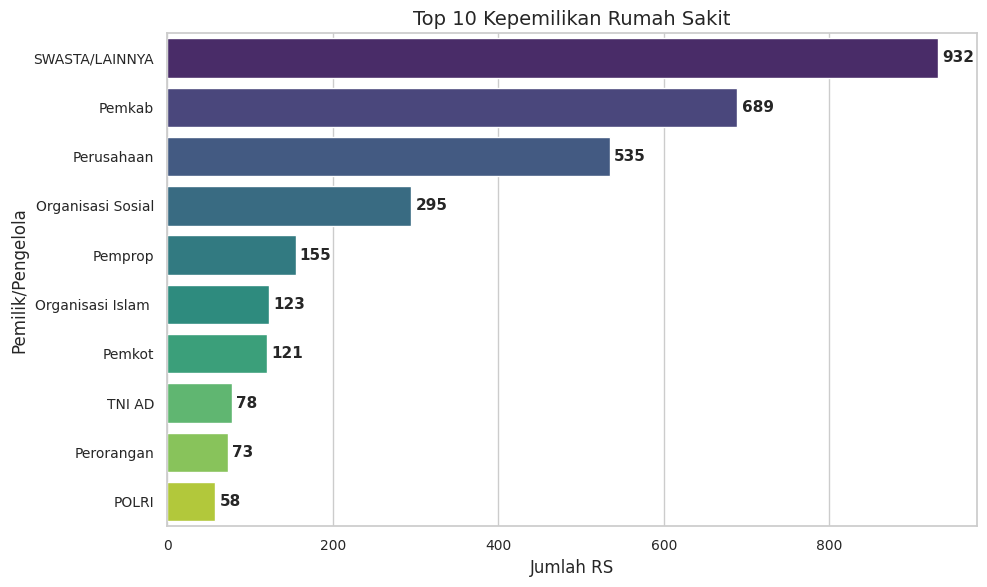

In [4]:
# 1.2 Distribusi Kepemilikan Rumah Sakit
if 'pemilik' in df_rs.columns:
    owner_counts = df_rs['pemilik'].value_counts().head(10) # Ambil top 10 jenis pemilik
    
    plt.figure(figsize=(10, 6))
    sns.barplot(y=owner_counts.index, x=owner_counts.values, palette="viridis")
    plt.title("Top 10 Kepemilikan Rumah Sakit")
    plt.xlabel("Jumlah RS")
    plt.ylabel("Pemilik/Pengelola")
    for i, val in enumerate(owner_counts.values):
        plt.text(val + 5, i, str(val), va='center', fontweight='bold')
        
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "kepemilikan_rs.png"), dpi=300)
    plt.show()

/tmp/ipykernel_2086/1164200236.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(y=prop_counts.index, x=prop_counts.values, palette="rocket")


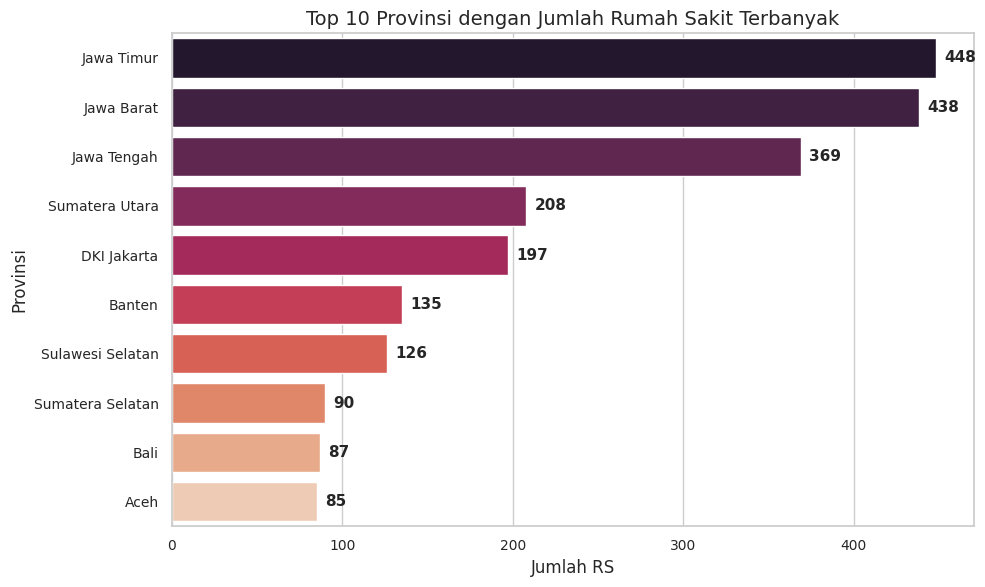

In [5]:
# 1.3 Distribusi Wilayah (Provinsi)
if 'nama_prop' in df_rs.columns:
    prop_counts = df_rs['nama_prop'].value_counts().head(10)
    
    plt.figure(figsize=(10, 6))
    sns.barplot(y=prop_counts.index, x=prop_counts.values, palette="rocket")
    plt.title("Top 10 Provinsi dengan Jumlah Rumah Sakit Terbanyak")
    plt.xlabel("Jumlah RS")
    plt.ylabel("Provinsi")
    for i, val in enumerate(prop_counts.values):
        plt.text(val + 5, i, str(val), va='center', fontweight='bold')
        
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "distribusi_provinsi_rs.png"), dpi=300)
    plt.show()

## 2. Analisis Kamus Normalisasi
Kamus normalisasi digunakan untuk memperbaiki kesalahan ketik (*typo*), singkatan, dan slang dari bahasa non-formal ke kata baku bahasa Indonesia. Analisis ini memberikan gambaran transformasi teks yang terjadi dalam pipeline preprocessing.

In [6]:
# Load Kamus Normalisasi
path_kamus = os.path.join(DATA_DIR, "raw/kamus_normalisasi.csv")
if os.path.exists(path_kamus):
    df_kamus = pd.read_csv(path_kamus)
    print(f"Kamus normalisasi berhasil dimuat. Total entri kata: {df_kamus.shape[0]}")
    display(df_kamus.head(10))
else:
    print(f"File tidak ditemukan di: {path_kamus}")

Kamus normalisasi berhasil dimuat. Total entri kata: 816


,kata_tidak_baku,kata_baku
0,yg,yang
1,tp,tapi
2,tpi,tapi
3,sy,saya
4,sya,saya
5,tdk,tidak
6,ga,tidak
7,gak,tidak
8,gk,tidak
9,ngga,tidak


/tmp/ipykernel_2086/1791288203.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=top_baku.values, y=top_baku.index, palette="mako")


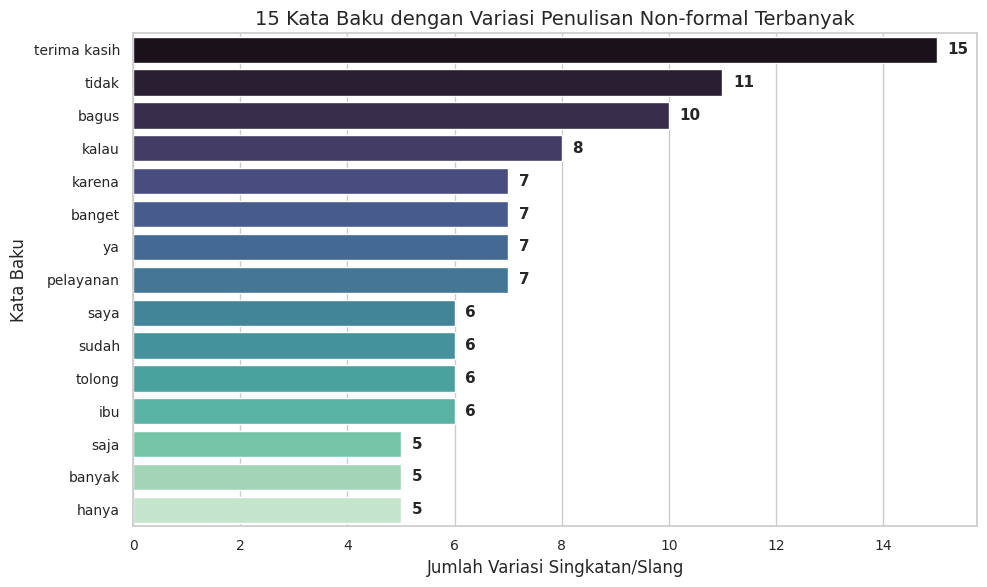

In [7]:
# 2.1 Analisis Pengelompokan Target Kata Baku Terbanyak
# Ini menunjukkan kata baku apa yang paling sering disingkat/salah ditulis dalam ulasan
top_baku = df_kamus['kata_baku'].value_counts().head(15)

plt.figure(figsize=(10, 6))
sns.barplot(x=top_baku.values, y=top_baku.index, palette="mako")
plt.title("15 Kata Baku dengan Variasi Penulisan Non-formal Terbanyak")
plt.xlabel("Jumlah Variasi Singkatan/Slang")
plt.ylabel("Kata Baku")
for i, val in enumerate(top_baku.values):
    plt.text(val + 0.2, i, str(val), va='center', fontweight='bold')
    
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "variasi_kata_normalisasi.png"), dpi=300)
plt.show()

## 3. Analisis Ulasan Google Maps (Processed)
Kita akan menggabungkan seluruh file CSV ulasan Google Maps dari rumah sakit yang di-scrape, menganalisis volume data, distribusi bintang (rating), panjang ulasan, dan tren data.

In [8]:
# Menggabungkan semua file ulasan gmaps
gmaps_files = glob.glob(os.path.join(DATA_DIR, "processed/hospital_reviews_gmaps_*.csv"))
print(f"Menemukan {len(gmaps_files)} file csv ulasan gmaps.")

li = []
for filename in gmaps_files:
    df_temp = pd.read_csv(filename, sep=";")
    li.append(df_temp)

if li:
    df_reviews = pd.concat(li, axis=0, ignore_index=True)
    print(f"Berhasil menggabungkan ulasan. Total ulasan: {df_reviews.shape[0]} baris.")
    display(df_reviews.head())
else:
    print("Tidak ada file ulasan yang berhasil dimuat.")

Menemukan 7 file csv ulasan gmaps.
Berhasil menggabungkan ulasan. Total ulasan: 140254 baris.


,hospital_id,hospital_name,author,rating,date,comment,latitude,longitude,scraping_timestamp
0,1171015,RS Umum Daerah Dr. Zainoel Abidin,Najwa syakila,5.0,13 jam lalu,"selama kami di aqsa 1 ruang 22, Alhamdullilah ...",5.563713,95.337588,2026-04-10 08:47:19
1,1171015,RS Umum Daerah Dr. Zainoel Abidin,Yenni Suryanida,5.0,1 hari lalu,selama mamak saya dirrawat Di rs za kami menda...,5.563713,95.337588,2026-04-10 08:47:19
2,1171015,RS Umum Daerah Dr. Zainoel Abidin,Bayu Ilhamsari,5.0,2 hari lalu,Selama di rawat di ruang aqsa 1 unit stroke ka...,5.563713,95.337588,2026-04-10 08:47:19
3,1171015,RS Umum Daerah Dr. Zainoel Abidin,kiki ananda,5.0,2 hari lalu,Pelayanan a sangat bagus dan ramah,5.563713,95.337588,2026-04-10 08:47:19
4,1171015,RS Umum Daerah Dr. Zainoel Abidin,Safridomas Simamora,1.0,5 hari lalu,"Katanya rumah sakit paripurna, tpi pelayanan u...",5.563713,95.337588,2026-04-10 08:47:19


/tmp/ipykernel_2086/3758434199.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="autumn_r")


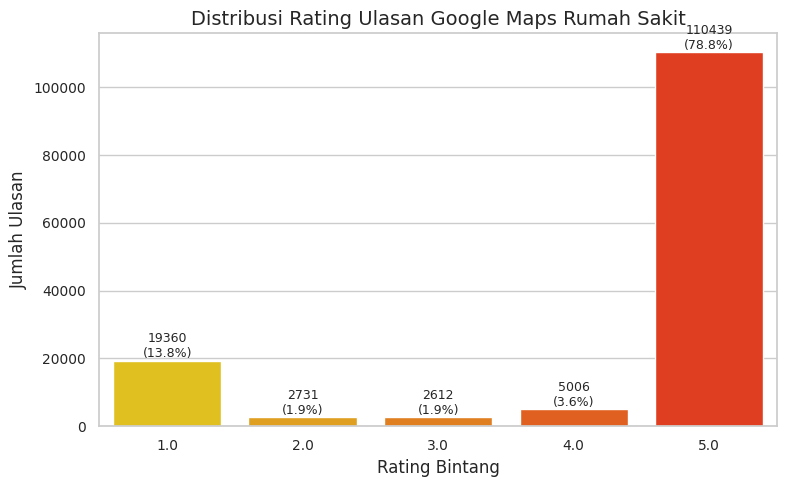

Rata-rata Rating Ulasan: 4.32 Bintang dari skala 5


In [9]:
# 3.1 Distribusi Rating Bintang (1 - 5)
if 'rating' in df_reviews.columns:
    rating_counts = df_reviews['rating'].value_counts().sort_index()
    
    plt.figure(figsize=(8, 5))
    sns.barplot(x=rating_counts.index, y=rating_counts.values, palette="autumn_r")
    plt.title("Distribusi Rating Ulasan Google Maps Rumah Sakit")
    plt.xlabel("Rating Bintang")
    plt.ylabel("Jumlah Ulasan")
    for i, val in enumerate(rating_counts.values):
        plt.text(i, val + 50, f"{val}\n({val/sum(rating_counts.values)*100:.1f}%)", ha='center', va='bottom', fontsize=9)
        
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "distribusi_rating_ulasan.png"), dpi=300)
    plt.show()
    
    # Deskriptif rating
    print(f"Rata-rata Rating Ulasan: {df_reviews['rating'].mean():.2f} Bintang dari skala 5")

--- Statistik Deskriptif Panjang Ulasan ---
            char_len       word_len
count  116722.000000  116722.000000
mean      132.340870      20.287367
std       207.431628      32.667235
min         1.000000       1.000000
25%        29.000000       4.000000
50%        69.000000      10.000000
75%       150.000000      23.000000
max      4093.000000     759.000000


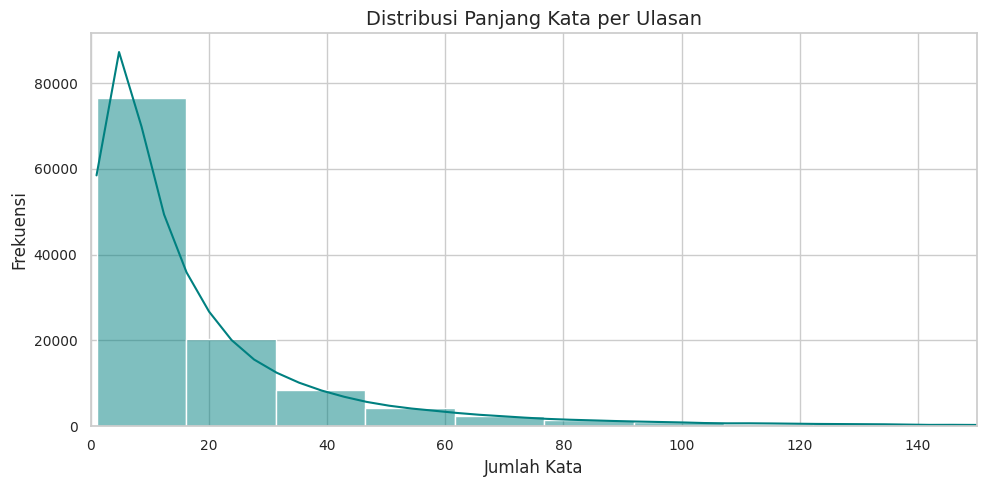

In [10]:
# 3.2 Analisis Panjang Karakter dan Kata Ulasan
# Hilangkan nilai kosong pada comment
df_comments = df_reviews[df_reviews['comment'].notna()].copy()

df_comments['char_len'] = df_comments['comment'].apply(len)
df_comments['word_len'] = df_comments['comment'].apply(lambda x: len(str(x).split()))

print("--- Statistik Deskriptif Panjang Ulasan ---")
print(df_comments[['char_len', 'word_len']].describe())

# Visualisasi Distribusi Panjang Kata
plt.figure(figsize=(10, 5))
sns.histplot(df_comments['word_len'], bins=50, kde=True, color="teal")
plt.title("Distribusi Panjang Kata per Ulasan")
plt.xlabel("Jumlah Kata")
plt.ylabel("Frekuensi")
plt.xlim(0, 150) # Batasi x agar visualisasi lebih fokus karena long tail
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "distribusi_panjang_kata_ulasan.png"), dpi=300)
plt.show()

/tmp/ipykernel_2086/2732681144.py:4: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='rating', y='word_len', data=df_comments, palette="Set2", showfliers=False)


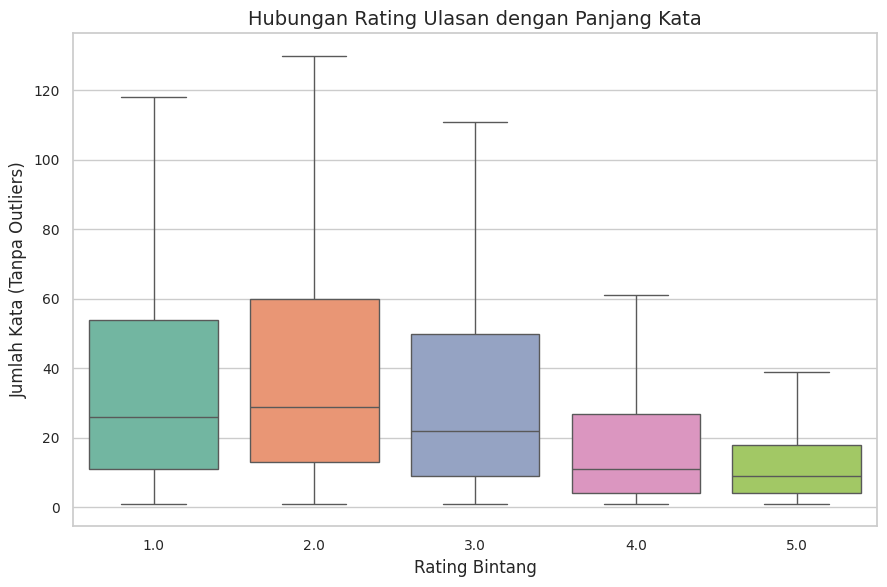

Rata-rata jumlah kata berdasarkan rating:
Bintang 1.0: 43.09 kata
Bintang 2.0: 48.41 kata
Bintang 3.0: 40.28 kata
Bintang 4.0: 23.29 kata
Bintang 5.0: 14.55 kata


In [11]:
# 3.3 Hubungan Rating Bintang dengan Panjang Ulasan
# Seringkali ulasan negatif (bintang 1-2) cenderung lebih panjang untuk menyampaikan keluhan
plt.figure(figsize=(9, 6))
sns.boxplot(x='rating', y='word_len', data=df_comments, palette="Set2", showfliers=False)
plt.title("Hubungan Rating Ulasan dengan Panjang Kata")
plt.xlabel("Rating Bintang")
plt.ylabel("Jumlah Kata (Tanpa Outliers)")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "box_rating_vs_panjang_kata.png"), dpi=300)
plt.show()

mean_word_by_rating = df_comments.groupby('rating')['word_len'].mean()
print("Rata-rata jumlah kata berdasarkan rating:")
for rating, mean_val in mean_word_by_rating.items():
    print(f"Bintang {rating}: {mean_val:.2f} kata")

## 4. Analisis Data Anotasi (Ground Truth GABSA)
Data anotasi manual digunakan untuk melatih dan mengevaluasi model Generative Aspect-Based Sentiment Analysis (GABSA) berbasis Qwen2.5-3B-Instruct. Kita akan membaca data anotasi ini dari berkas JSONL (`combined_labeled_data.jsonl`), lalu menganalisis distribusi aspek, sentimen, dan panjang evidence span.

In [32]:
# Load data anotasi dari JSONL
path_annotated = os.path.join(DATA_DIR, "annotations/label_results/llm_annotated_data.jsonl")

annotations_list = []
if os.path.exists(path_annotated):
    with open(path_annotated, "r", encoding="utf-8") as f:
        for line in f:
            if line.strip():
                annotations_list.append(json.loads(line))
    print(f"Berhasil memuat {len(annotations_list)} data ulasan dianotasi (Ground Truth).")
else:
    print(f"File tidak ditemukan di: {path_annotated}")

Berhasil memuat 6367 data ulasan dianotasi (Ground Truth).


In [33]:
# Ekstraksi label aspek dan sentimen dari data anotasi
# Format anotasi doccano: {'text': '...', 'label': [[start, end, 'aspek__sentimen'], ...]}
parsed_labels = []

for item in annotations_list:
    text = item.get('text', '')
    labels = item.get('label', [])
    
    for start, end, full_label in labels:
        # Split aspek dan sentimen (contoh: pelayanan__positif)
        if '__' in full_label:
            aspect, sentiment = full_label.split('__')
        else:
            # fallback jika format berbeda
            aspect = full_label
            sentiment = 'unknown'
            
        evidence_span = text[start:end]
        parsed_labels.append({
            "aspect": aspect,
            "sentiment": sentiment,
            "evidence": evidence_span,
            "span_length": end - start
        })

df_ann = pd.DataFrame(parsed_labels)
print(f"Berhasil mengekstrak {df_ann.shape[0]} entri anotasi multi-aspek dari {len(annotations_list)} ulasan.")
display(df_ann.head(10))

Berhasil mengekstrak 9078 entri anotasi multi-aspek dari 6367 ulasan.


,aspect,sentiment,evidence,span_length
0,fasilitas,negatif,"Kecewa obat nya sering gak ada, di rumah beli ...",53
1,waktu_tunggu,negatif,Ambil hasil 1 berkas Medical Check up bulan De...,116
2,waktu_tunggu,negatif,"menunggu atministrasi aja luar biasa lamanya, ...",87
3,fasilitas,negatif,Terlalu banyak anak² yg ikut diruang rawat ina...,138
4,pelayanan,negatif,rumah sakit tapi banyak orang merokok di sekit...,105
5,fasilitas,negatif,"bantal nya kagak ada, leher pasien sakit oi, u...",203
6,fasilitas,negatif,fasilitas di kamar rawat inap banyak yang suda...,125
7,kebersihan,negatif,toilet yang kurang bersih bahkan cenderung bau...,77
8,pelayanan,negatif,staf pelayanan tidak ramah kepada masyarakat m...,61
9,tenaga_medis,negatif,Tenaga medis di sini sangat jelak mereka hanya...,115


/tmp/ipykernel_2086/2258386134.py:5: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `y` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=aspect_counts.values, y=aspect_counts.index, palette="viridis")


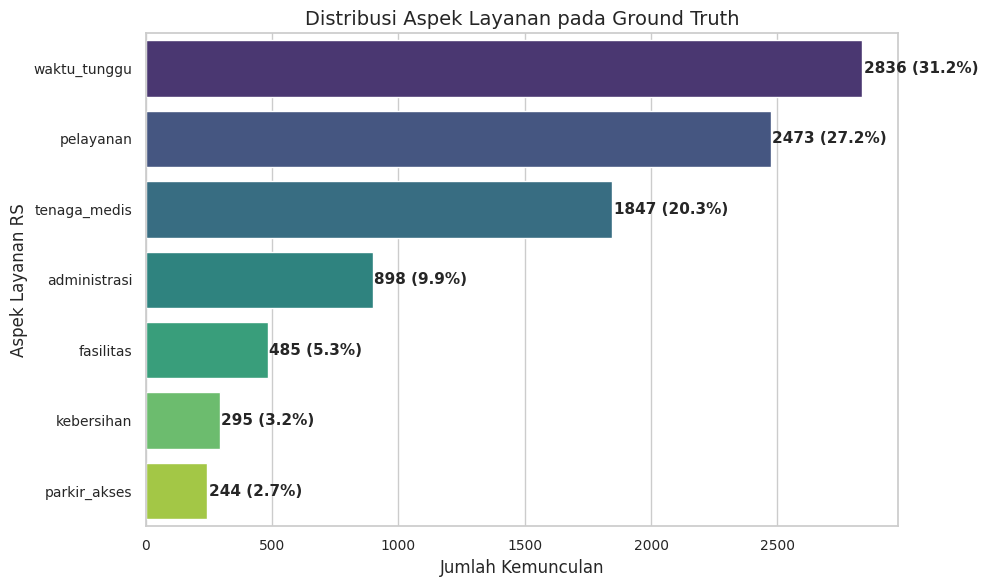

In [34]:
# 4.1 Distribusi 8 Aspek Layanan Rumah Sakit
aspect_counts = df_ann['aspect'].value_counts()

plt.figure(figsize=(10, 6))
sns.barplot(x=aspect_counts.values, y=aspect_counts.index, palette="viridis")
plt.title("Distribusi Aspek Layanan pada Ground Truth")
plt.xlabel("Jumlah Kemunculan")
plt.ylabel("Aspek Layanan RS")
for i, val in enumerate(aspect_counts.values):
    plt.text(val + 5, i, f"{val} ({val/sum(aspect_counts.values)*100:.1f}%)", va='center', fontweight='bold')
    
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "distribusi_aspek_ground_truth.png"), dpi=300)
plt.show()

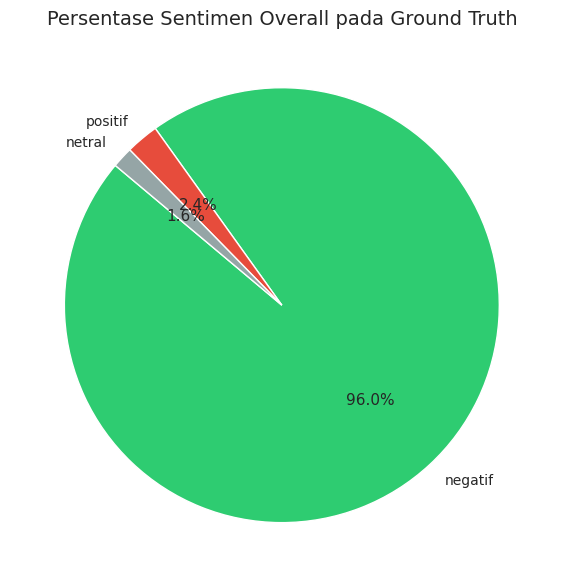

sentiment
negatif    8715
positif     222
netral      141
Name: count, dtype: int64


In [35]:
# 4.2 Distribusi Sentimen Overall
sentiment_counts = df_ann['sentiment'].value_counts()

plt.figure(figsize=(6, 6))
plt.pie(sentiment_counts.values, labels=sentiment_counts.index, autopct='%1.1f%%', 
        startangle=140, colors=["#2ecc71", "#e74c3c", "#95a5a6"])
plt.title("Persentase Sentimen Overall pada Ground Truth")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "pie_sentimen_ground_truth.png"), dpi=300)
plt.show()

print(df_ann['sentiment'].value_counts())

--- Jumlah Kemunculan Aspek vs Sentimen ---
sentiment     negatif  netral  positif
aspect                                
administrasi      865      26        7
fasilitas         462       9       14
kebersihan        280       3       12
parkir_akses      236       5        3
pelayanan        2311      47      115
tenaga_medis     1756      30       61
waktu_tunggu     2805      21       10


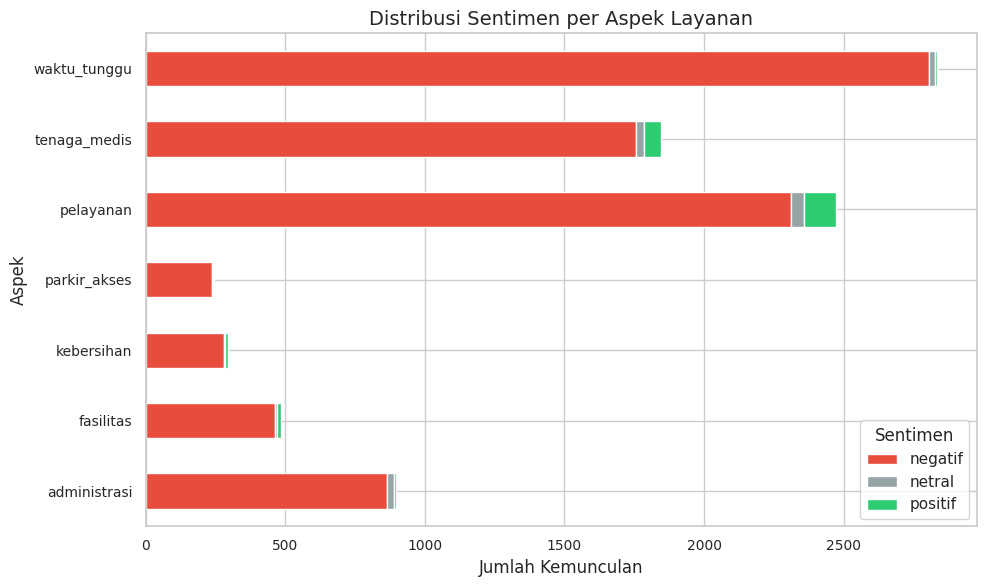

In [36]:
# 4.3 Persilangan Aspek vs Sentimen (Crosstab)
cross_tab = pd.crosstab(df_ann['aspect'], df_ann['sentiment'])
cross_tab_pct = pd.crosstab(df_ann['aspect'], df_ann['sentiment'], normalize='index') * 100

print("--- Jumlah Kemunculan Aspek vs Sentimen ---")
print(cross_tab)

# Stacked Bar Chart Aspek vs Sentimen
cross_tab.plot(kind='barh', stacked=True, color=["#e74c3c", "#95a5a6", "#2ecc71"], figsize=(10, 6))
plt.title("Distribusi Sentimen per Aspek Layanan")
plt.xlabel("Jumlah Kemunculan")
plt.ylabel("Aspek")
plt.legend(title="Sentimen")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "sentimen_per_aspek.png"), dpi=300)
plt.show()

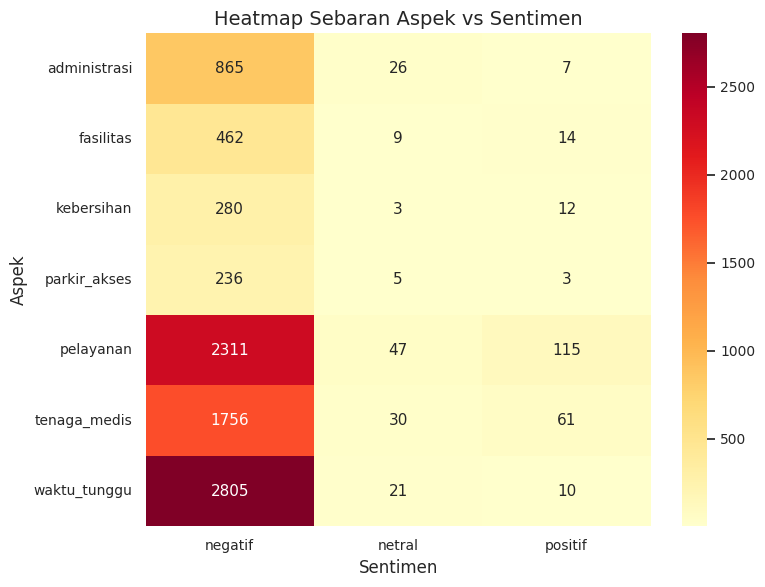

In [37]:
# Heatmap Korelasi Aspek vs Sentimen
plt.figure(figsize=(8, 6))
sns.heatmap(cross_tab, annot=True, cmap="YlOrRd", fmt="d", cbar=True)
plt.title("Heatmap Sebaran Aspek vs Sentimen")
plt.ylabel("Aspek")
plt.xlabel("Sentimen")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "heatmap_aspek_sentimen.png"), dpi=300)
plt.show()

/tmp/ipykernel_47357/1794742453.py:6: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.boxplot(x='aspect', y='evidence_word_len', data=df_ann, palette="Pastel1")


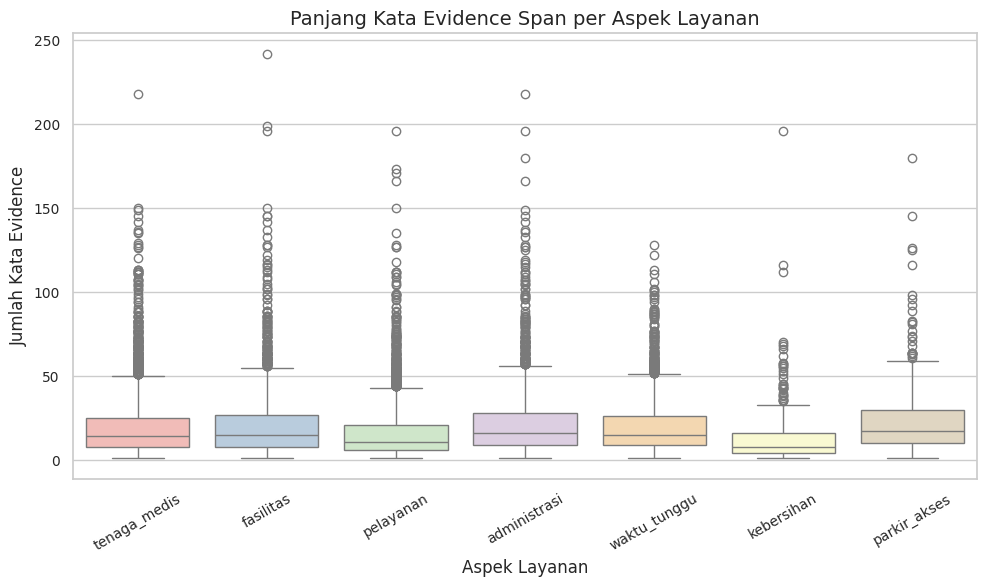

Rata-rata panjang kata evidence span per aspek:
aspect
administrasi    21.973368
fasilitas       21.122397
kebersihan      12.379585
parkir_akses    22.646235
pelayanan       16.090171
tenaga_medis    19.444491
waktu_tunggu    19.253776
Name: evidence_word_len, dtype: float64


In [20]:
# 4.4 Analisis Karakteristik Evidence Span
# Menganalisis panjang kata/karakter dari teks bukti yang melandasi pelabelan aspek
df_ann['evidence_word_len'] = df_ann['evidence'].apply(lambda x: len(str(x).split()))

plt.figure(figsize=(10, 6))
sns.boxplot(x='aspect', y='evidence_word_len', data=df_ann, palette="Pastel1")
plt.title("Panjang Kata Evidence Span per Aspek Layanan")
plt.xlabel("Aspek Layanan")
plt.ylabel("Jumlah Kata Evidence")
plt.xticks(rotation=30)
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "boxplot_evidence_len_per_aspek.png"), dpi=300)
plt.show()

print("Rata-rata panjang kata evidence span per aspek:")
print(df_ann.groupby('aspect')['evidence_word_len'].mean())

## 5. Analisis Data Latih Task B (Summary Generation)
Task B dalam penelitian ini adalah menghasilkan ringkasan laporan rekomendasi strategis manajemen (*Strategic Management Summary Generation*) dari statistik agregat ulasan. Kita akan menganalisis dataset latih Task B dari berkas `summary_training_prep.csv`.

In [21]:
# Load data Task B
path_summary = os.path.join(DATA_DIR, "annotations/summary_data_result.xlsx")

if os.path.exists(path_summary):
    df_sum = pd.read_excel(path_summary)
    print(f"Data Latih Summary berhasil dimuat. Total sampel: {df_sum.shape[0]}")
    display(df_sum.head())
else:
    print(f"File tidak ditemukan di: {path_summary}")

Data Latih Summary berhasil dimuat. Total sampel: 100


,sample_id,input_stats,target_summary
0,1,"{""total_reviews_analyzed"": 40, ""aspect_distrib...",**Ringkasan Eksekutif: **Laporan ini menganali...
1,2,"{""total_reviews_analyzed"": 40, ""aspect_distrib...",**Ringkasan Eksekutif:** Analisis terhadap 40 ...
2,3,"{""total_reviews_analyzed"": 40, ""aspect_distrib...",**Ringkasan Eksekutif:** Berdasarkan data 40 u...
3,4,"{""total_reviews_analyzed"": 40, ""aspect_distrib...",**Ringkasan Eksekutif:** Laporan dari 40 ulasa...
4,5,"{""total_reviews_analyzed"": 40, ""aspect_distrib...",**Ringkasan Eksekutif:** Analisis 40 ulasan me...


Rata-rata ulasan dianalisis per batch simulasi: 50.0 ulasan
Rentang jumlah ulasan per batch: 30 - 80 ulasan


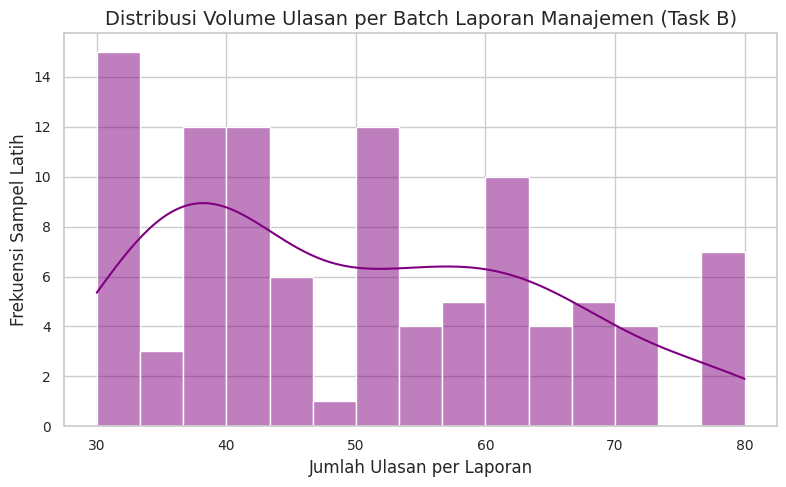

In [22]:
# 5.1 Analisis Distribusi Jumlah Ulasan yang Dianalisis per Batch
# Data input_stats tersimpan sebagai string JSON. Kita akan menguraikannya untuk mengambil statistik.

def extract_total_reviews(json_str):
    try:
        d = json.loads(json_str)
        return d.get('total_reviews_analyzed', 0)
    except:
        return 0

df_sum['total_reviews_batch'] = df_sum['input_stats'].apply(extract_total_reviews)

print(f"Rata-rata ulasan dianalisis per batch simulasi: {df_sum['total_reviews_batch'].mean():.1f} ulasan")
print(f"Rentang jumlah ulasan per batch: {df_sum['total_reviews_batch'].min()} - {df_sum['total_reviews_batch'].max()} ulasan")

plt.figure(figsize=(8, 5))
sns.histplot(df_sum['total_reviews_batch'], bins=15, kde=True, color="purple")
plt.title("Distribusi Volume Ulasan per Batch Laporan Manajemen (Task B)")
plt.xlabel("Jumlah Ulasan per Laporan")
plt.ylabel("Frekuensi Sampel Latih")
plt.tight_layout()
plt.savefig(os.path.join(PLOT_DIR, "distribusi_ulasan_per_batch_task_b.png"), dpi=300)
plt.show()

--- Statistik Deskriptif Panjang Ringkasan (Target Summary) ---
count    100.000000
mean     131.870000
std       14.421263
min       87.000000
25%      127.000000
50%      132.000000
75%      141.250000
max      153.000000
Name: summary_word_len, dtype: float64


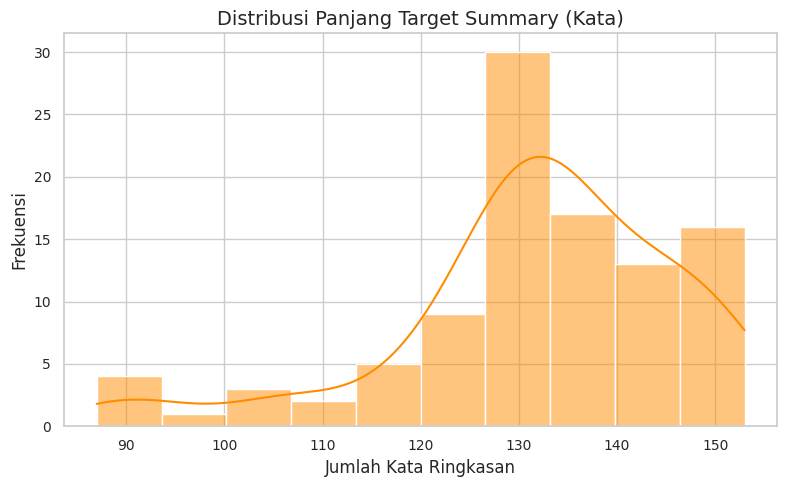

In [23]:
# 5.2 Analisis Panjang Target Summary
# Menghitung panjang ringkasan rekomendasi (target_summary) dalam jumlah kata
# Hanya evaluasi baris yang target_summary-nya sudah terisi
df_filled_sum = df_sum[df_sum['target_summary'].notna() & (df_sum['target_summary'] != "")].copy()

if not df_filled_sum.empty:
    df_filled_sum['summary_word_len'] = df_filled_sum['target_summary'].apply(lambda x: len(str(x).split()))
    
    print("--- Statistik Deskriptif Panjang Ringkasan (Target Summary) ---")
    print(df_filled_sum['summary_word_len'].describe())
    
    plt.figure(figsize=(8, 5))
    sns.histplot(df_filled_sum['summary_word_len'], bins=10, kde=True, color="darkorange")
    plt.title("Distribusi Panjang Target Summary (Kata)")
    plt.xlabel("Jumlah Kata Ringkasan")
    plt.ylabel("Frekuensi")
    plt.tight_layout()
    plt.savefig(os.path.join(PLOT_DIR, "distribusi_panjang_target_summary.png"), dpi=300)
    plt.show()
else:
    print("Catatan: Kolom target_summary belum terisi untuk data latih baru (siap di-annotate/diisi model).")

## 6. Rangkuman Insight Statistik untuk Draf Skripsi
Jalankan cell di bawah ini untuk mencetak rangkuman data final dalam format teks terstruktur yang dapat disalin sebagai fakta statistik utama di Bab 3 & Bab 4 Skripsi Anda.

In [24]:
print("========== STATISTIK DESKRIPTIF DATASET PENELITIAN GABSA RS ==========\n")

# RS Stats
print(f"1. DATA MASTER RS (SIRS & API):")
print(f"   - Total Rumah Sakit Terdaftar          : {df_rs.shape[0]}")
if 'kelas' in df_rs.columns:
    for cls, val in df_rs['kelas'].value_counts().items():
        print(f"     * RS Kelas {cls:<27}: {val} unit ({val/df_rs.shape[0]*100:.2f}%)")

# Kamus Stats
print(f"\n2. KAMUS NORMALISASI BAHASA NON-FORMAL:")
print(f"   - Total Entri Pemetaan Kata            : {df_kamus.shape[0]} kata")

# Reviews Stats
print(f"\n3. ULASAN GOOGLE MAPS:")
print(f"   - Total Seluruh Ulasan Terkumpul       : {df_reviews.shape[0]} ulasan")
print(f"   - Total Ulasan Mengandung Teks         : {df_comments.shape[0]} ulasan ({df_comments.shape[0]/df_reviews.shape[0]*100:.2f}%)")
print(f"   - Rata-rata Rating Ulasan              : {df_reviews['rating'].mean():.2f} Bintang")
print(f"   - Rata-rata Jumlah Kata per Ulasan     : {df_comments['word_len'].mean():.1f} kata")

# Annotations Stats
print(f"\n4. DATA ANOTASI GROUND TRUTH (GABSA):")
print(f"   - Total Ulasan Dianotasi               : {len(annotations_list)} ulasan")
print(f"   - Total Pasangan Aspek-Sentimen Labeled: {df_ann.shape[0]} entri")
print(f"   - Rata-rata Aspek per Ulasan           : {df_ann.shape[0]/len(annotations_list):.2f} aspek")
print(f"   - Rata-rata Panjang Span Bukti (Kata)  : {df_ann['evidence_word_len'].mean():.1f} kata")
print(f"\n   - Distribusi Aspek dan Sentimen Labeled:")
for asp, val in df_ann['aspect'].value_counts().items():
    pos = df_ann[(df_ann['aspect'] == asp) & (df_ann['sentiment'] == 'positif')].shape[0]
    neg = df_ann[(df_ann['aspect'] == asp) & (df_ann['sentiment'] == 'negatif')].shape[0]
    net = df_ann[(df_ann['aspect'] == asp) & (df_ann['sentiment'] == 'netral')].shape[0]
    print(f"     * Aspek {asp:<20} : {val:<4} entri | Positif: {pos:<3} | Negatif: {neg:<3} | Netral: {net:<3}")

print("\n=====================================================================")

========== STATISTIK DESKRIPTIF DATASET PENELITIAN GABSA RS ==========

1. DATA MASTER RS (SIRS & API):
   - Total Rumah Sakit Terdaftar          : 3300
     * RS Kelas C                          : 1803 unit (54.64%)
     * RS Kelas D                          : 870 unit (26.36%)
     * RS Kelas B                          : 454 unit (13.76%)
     * RS Kelas A                          : 85 unit (2.58%)
     * RS Kelas D PRATAMA                  : 82 unit (2.48%)
     * RS Kelas Belum Ditetapkan           : 3 unit (0.09%)
     * RS Kelas Non Kelas                  : 3 unit (0.09%)

2. KAMUS NORMALISASI BAHASA NON-FORMAL:
   - Total Entri Pemetaan Kata            : 816 kata

3. ULASAN GOOGLE MAPS:
   - Total Seluruh Ulasan Terkumpul       : 140254 ulasan
   - Total Ulasan Mengandung Teks         : 116722 ulasan (83.22%)
   - Rata-rata Rating Ulasan              : 4.32 Bintang
   - Rata-rata Jumlah Kata per Ulasan     : 20.3 kata

4. DATA ANOTASI GROUND TRUTH (GABSA):
   - Total Ulasan Dian